# Read each token prefix once

**Mason McBride · An Outlines Core experiment**

Outlines compiles a constraint into an index: from each automaton state,
which vocabulary tokens are valid, and where do they lead?

The original constructor walks every token's bytes separately.
Tokens share prefixes. Their walks can share computation too.

In [1]:
import hashlib, json, statistics
from pathlib import Path
from IPython.display import SVG, display
from notebook_analysis import plot_results
root = Path.cwd()
provenance = json.loads((root/'SOURCE_PROVENANCE.json').read_text())
for name, expected in provenance['measurements_sha256'].items():
    assert hashlib.sha256((root/name).read_bytes()).hexdigest() == expected
datasets = {n: json.loads((root/f'data/{n}.json').read_text()) for n in ['gpt2','qwen','synthetic']}

## Share the walk

Take `return`, `returned`, and `returns`. Separate walks consume
**6 + 8 + 7 = 21 bytes**. A trie consumes the shared `return` prefix
once, then follows three suffix edges: **9 byte transitions**.
These counts assume every path survives.

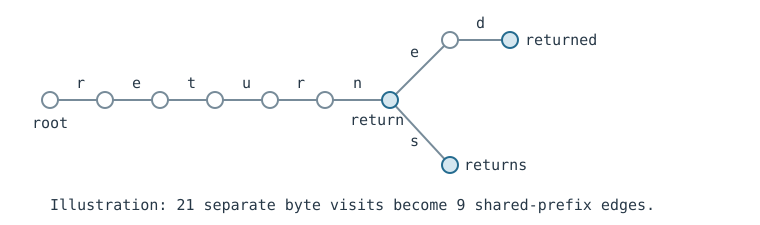

In [2]:
display(SVG(filename=str(root/'figures/prefix_trie.svg')))

Why is that safe? A deterministic automaton reaches the same state after
the same prefix. Writing $\delta^*$ for a walk over bytes:

$$\delta^*(q,xy)=\delta^*(\delta^*(q,x),y).$$

Carry the current DFA state down each trie edge. Record the state at each
token endpoint. If a prefix reaches a dead state, skip its entire subtree.

```text
visit(node, state):
    record this state for tokens ending here
    for byte, child in node.children:
        next = DFA.next(state, byte)
        if next survives:
            visit(child, next)
```

This illustrates the traversal. The Rust implementation uses an explicit
stack, so a long token does not consume the call stack.

<details><summary>The traversal — exact Rust source</summary>

```rust
stack.push((0, current_state));
while let Some((node_id, state)) = stack.pop() {
    let node = &self.nodes[node_id];
    if let Some(rank) = node.terminal {
        candidates[rank] = Some(state);
        if COUNT {
            work.surviving_tokens += 1;
        }
    }
    for &(byte, child) in &self.edges[node.edge_start..node.edge_start + node.edge_len]
    {
        let next = dfa.next_state(state, byte);
        if COUNT {
            work.byte_transitions += 1;
        }
        if !dfa.is_dead_state(next) && !dfa.is_quit_state(next) {
            stack.push((child, next));
        }
    }
}
```

</details>

## Preserve the behavior

The trie stores **bytes**, because tokenizer entries may contain only part
of a UTF-8 character. Tokens can also end inside another token's path.

Traversal changes encounter order. The prototype restores the original
vocabulary order before inserting destinations, preserving duplicate-ID
overwrites and which error is reported first. That bookkeeping costs time.

The original constructor stays intact. Tests compare complete indexes and
exact errors across **3,000 generated cases**; a separate finite-language
oracle checks valid continuations and EOS.

## Pay for preparation

A vocabulary trie can serve several constraints. Measure both ways:
**build it for each index**, or **prepare it once and reuse it**.

For Qwen's JSON record, construction falls from **322 ms to 128 ms**
including preparation, or **99 ms** with the vocabulary trie reused.
For a three-digit constraint, preparation overwhelms the savings.

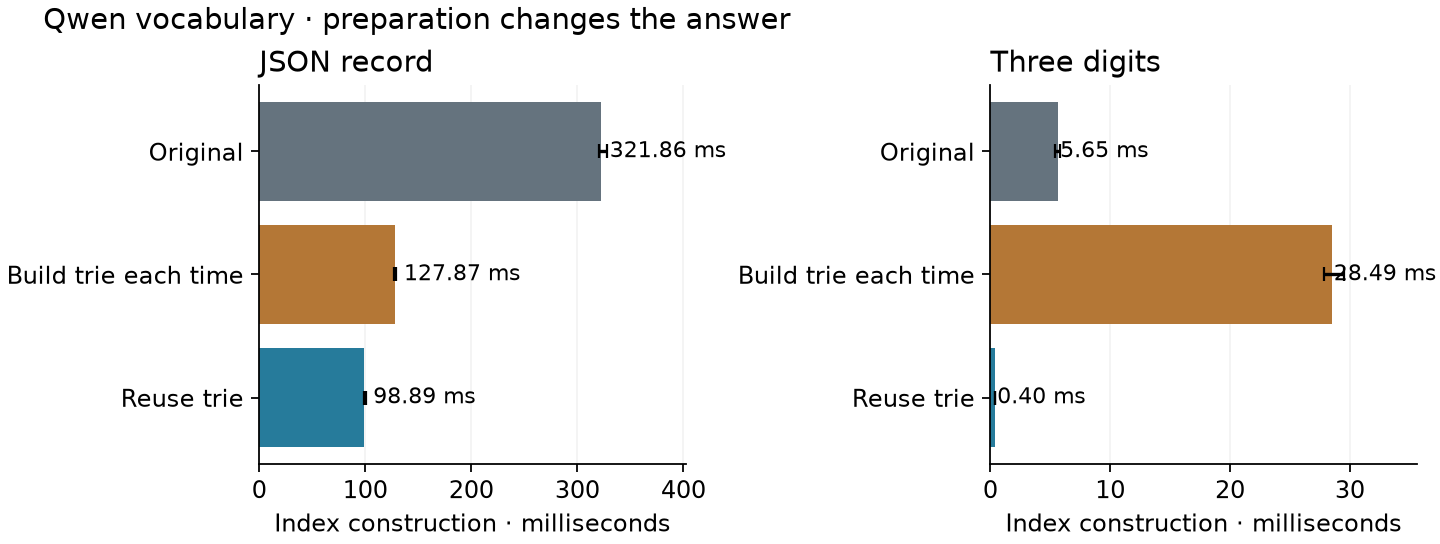

In [3]:
plot_results(datasets, root)

Bars are medians of 21 samples on an **i7-12700K**; whiskers are 
95% bootstrap intervals. Every variant rebuilds the DFA and index.
Only the prepared variant reuses the vocabulary trie.

Saved work is not the whole cost. On synthetic permissive text, sharing
prefixes performs **2.82× fewer byte transitions**, yet prepared construction
slows from **2.99 ms to 3.88 ms**. Traversal and bookkeeping can outweigh
the transitions they remove.

The useful design is an optional, reusable vocabulary preparation step.
The measurements support particular constructor workloads; generation
throughput and Python integration remain unmeasured.

<details><summary>Implementation, checks, and measurement details</summary>

Nodes and edges are packed in vectors. Each terminal retains every associated
token ID. Rank-indexed candidates preserve the reference's insertion order;
the output index representation and default constructor are unchanged.

Rust coverage includes empty and prefix tokens, duplicate IDs, malformed
constraints, split UTF-8, a 20,000-byte token, and finite-language checks.
Seventeen existing tests and six added test functions passed in the recorded
experiment, plus two normalization tests. Formatting and Clippy passed.

Six constraints were measured against GPT-2, Qwen, and a synthetic control.
Each variant received 21 samples with rotating order after warmup. A release
Rust 1.90.0 build ran on one pinned logical CPU; frequency was not locked and
the host was shared. Normalization, equality checks, and counters were outside
timings. Returned index destruction was excluded; temporary trie destruction
was included in the one-off variant. Separate-process repetitions are saved.

The Qwen trie estimates 20.23 MB of allocated vector payload; this excludes
allocator metadata, temporary build storage, and traversal scratch. Peak
memory was not measured. No universal adoption threshold is established.

</details>

[Implementation](https://github.com/masonmcbride/outlines-core/blob/trie-prefix-sharing/src/index/trie.rs) ·
[Tests](https://github.com/masonmcbride/outlines-core/blob/trie-prefix-sharing/tests/trie_equivalence.rs) ·
[Notebook](Prefix_Sharing.ipynb) · [Reproduce](README.md) ·
[Raw Qwen samples](data/qwen.json) · [Source hashes](SOURCE_PROVENANCE.json)

Based on [Outlines Core `116a7c3`](https://github.com/dottxt-ai/outlines-core/tree/116a7c381b446814fdfc9b2b28bea7ca4f900aae).